In [ ]:
!pip install ultralytics opencv-python numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.7 MB/s eta 0:00:00


In [ ]:
import cv2
import numpy as np
import json
import uuid
import math
from ultralytics import YOLO
from google.colab import files
import matplotlib.pyplot as plt


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# Pipeline flow

Video
  → [Pose Estimation]   detects body joints per frame


  → [EMA Smoothing]     removes  detection noise from keypoints( sometimes there isnt any movement yet)


  → [Rep Counting]      counts squats & push-ups

  
  → [Form Assessment]   checks joint angles for correctness
  
  
  → [JSON Output]       saves all results structured

In [ ]:
def upload_video(video_path):
  cap = cv2.VideoCapture(video_path)

  fps    = cap.get(cv2.CAP_PROP_FPS)
  width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
  height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
  total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

  print(f"FPS     : {fps}")
  print(f"Size    : {width} x {height}")
  print(f"Frames  : {total}")

  cap.release()

  return fps, width, height, total

In [ ]:
video_path = "/content/CV_both_exercises_video_perfect_form.mp4"
fps, width, height, total = upload_video(video_path)


FPS     : 25.0
Size    : 1280 x 720
Frames  : 2044


In [ ]:
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

First we'll use a perfect pushup/squat video

# Pose Estimation
 For each frame of the video, YOLOv8's pose model detects a person and returns 17 keypoints (joints like shoulders, hips, knees, ankles, wrists, etc.) as (x, y) coordinates.

In [ ]:
model = YOLO("yolov8s-pose.pt")

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

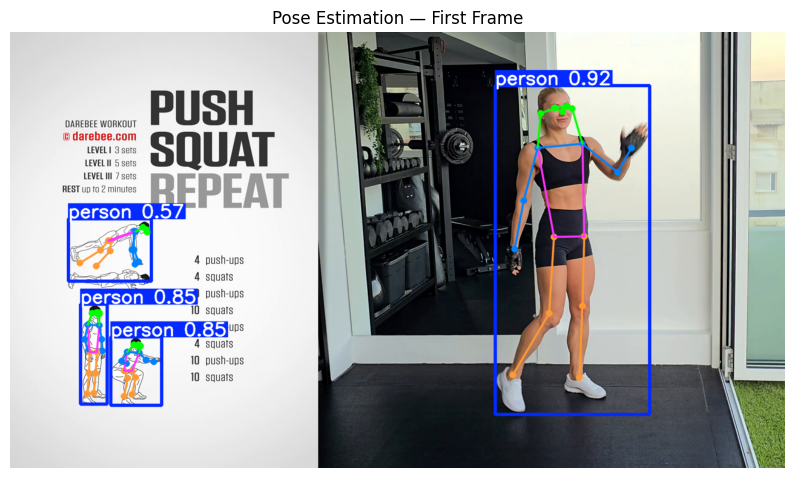

In [ ]:
results = model(frame, verbose=False)

# Plot keypoints on the frame
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Pose Estimation — First Frame")
plt.show()

In [ ]:
all_keypoints = [] #will store keypoint for all our frames
current_frame = 0

cap = cv2.VideoCapture(video_path)

while True:
    ret, frame = cap.read() # ret short for return ,boolean returned by cap.read,
    # ret= true means frame was read successfully
    if not ret:
        break

    if current_frame % 2 == 0: # only process even frames
        results = model(frame, verbose=False)  # runs YOLOv8 pose
        if results[0].keypoints is not None and len(results[0].keypoints.xy) > 0:
            kps = results[0].keypoints.xy[0].cpu().numpy() # extracts (x,y) of 17 keypoints
        else:
            kps = None # if no person detected, store None
        all_keypoints.append(kps)

    current_frame+= 1

cap.release()
print(f"Processed frames: {len(all_keypoints)}")

Processed frames: 1022


# Keypoint Smoothing (EMA)
Raw keypoint coordinates jump around slightly between frames due to detection noise. EMA blends each frame's keypoints with the previous ones using a formula


smoothed = alpha * current + (1 - alpha) * previous


So if alpha is close to 1:

The smoothed position is mostly based on what YOLO detected right now
Less influence from previous frames
Result: more responsive but jittery

If alpha is close to 0:

The smoothed position is mostly based on what was detected in past frames
Less influence from the current frame
Result: very smooth but slow to react to real movement

In [ ]:
# alpha = blending factor
               # 0.5 = 50% current + 50% previous (balanced)
               # closer to 1 = trust current frame more (less smooth)
               # closer to 0 = trust previous more (more smooth)


def smooth_keypoints(all_keypoints, alpha=0.5):
    smoothed = []
    prev = None

    for kps in all_keypoints:
        if kps is None:
            smoothed.append(prev)  # person not detected this frame so use last detected frame
            continue

        if prev is None: ## very first frame, nothing to blend with , so add it as is
            smoothed.append(kps)
            prev = kps
            continue

        # EMA formula: new = alpha * current + (1 - alpha) * previous
        smoothed_kps = alpha * kps + (1 - alpha) * prev
        smoothed.append(smoothed_kps)
        prev = smoothed_kps

    return smoothed

smoothed_keypoints = smooth_keypoints(all_keypoints, alpha=0.5)

print(f"Total smoothed frames : {len(smoothed_keypoints)}")

Total smoothed frames : 1022


visualizes the effect of EMA smoothing

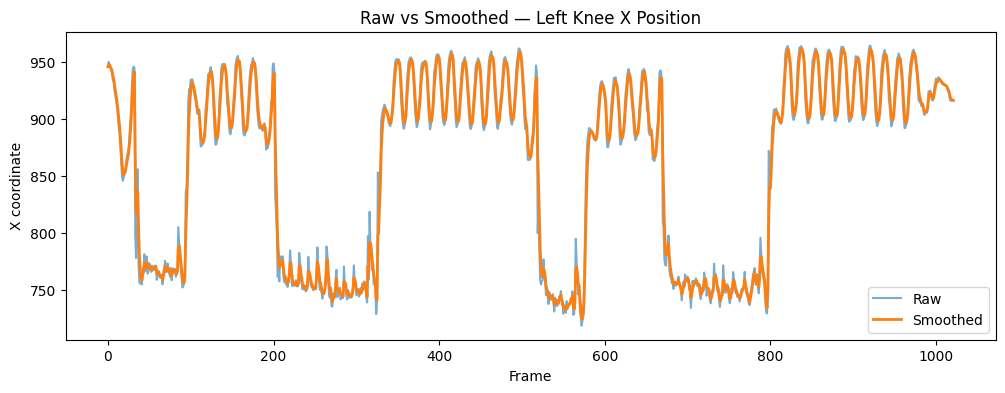

In [ ]:
# Compare keypoint 13 (left knee) x-coordinate across frames
joint_idx = 13

raw_x =      [kps[joint_idx][0] if kps is not None else np.nan for kps in all_keypoints]
smoothed_x = [kps[joint_idx][0] if kps is not None else np.nan for kps in smoothed_keypoints]

plt.figure(figsize=(12, 4))
plt.plot(raw_x,      label="Raw",      alpha=0.6)
plt.plot(smoothed_x, label="Smoothed", linewidth=2)
plt.title("Raw vs Smoothed — Left Knee X Position")
plt.xlabel("Frame")
plt.ylabel("X coordinate")
plt.legend()
plt.show()

raw is the orange line because the curve is smoothed, the blue is the raw since it has spikes

# Joint Angle Calculation

In [ ]:
def calculate_angle(A, B, C):
    """
    Calculate the angle at point B formed by points A, B, C
    A, B, C are (x, y) coordinates
    """
    A = np.array(A)
    B = np.array(B)
    C = np.array(C)

    BA = A - B #want the angle AT B, so B is the center
    BC = C - B

    cosine = np.dot(BA, BC) / (np.linalg.norm(BA) * np.linalg.norm(BC) + 1e-6)
    angle = np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))

    return angle

In [ ]:
# YOLOv8 pose keypoint indices
# 5=left shoulder, 6=right shoulder
# 7=left elbow,    8=right elbow
# 9=left wrist,    10=right wrist
# 11=left hip,     12=right hip
# 13=left knee,    14=right knee
# 15=left ankle,   16=right ankle

LEFT_HIP    = 11
LEFT_KNEE   = 13
LEFT_ANKLE  = 15

LEFT_SHOULDER = 5
LEFT_ELBOW    = 7
LEFT_WRIST    = 9

kps = smoothed_keypoints[100]  # pick any frame

knee_angle   = calculate_angle(kps[LEFT_HIP], kps[LEFT_KNEE], kps[LEFT_ANKLE])
elbow_angle  = calculate_angle(kps[LEFT_SHOULDER], kps[LEFT_ELBOW], kps[LEFT_WRIST])

print(f"Knee angle  : {knee_angle:.1f}°")
print(f"Elbow angle : {elbow_angle:.1f}°")

Knee angle  : 168.8°
Elbow angle : 164.4°


# Knee angles interpretation

* 170° - 180° = fully straight (standing)
* 120° - 150° = slightly bent
* 80° - 100° = deep squat
* < 80° = very deep / past parallel

# Elbow angle interpretations

* 170° - 180°  = fully straight (arms locked out)
* 120° - 150° = slightly bent
* 80° - 100°  = proper push-up bottom position
* < 80° = very deep bend

In [ ]:
#left side

left_knee_angles  = []
left_elbow_angles = []

#calculate_angle on every frame of the video
for kps in smoothed_keypoints:
    if kps is None:  # no person detected this frame
        left_knee_angles.append(np.nan)
        left_elbow_angles.append(np.nan)
        continue

    left_knee_angles.append(calculate_angle(kps[LEFT_HIP],  kps[LEFT_KNEE],  kps[LEFT_ANKLE]))
    left_elbow_angles.append(calculate_angle(kps[LEFT_SHOULDER], kps[LEFT_ELBOW], kps[LEFT_WRIST]))

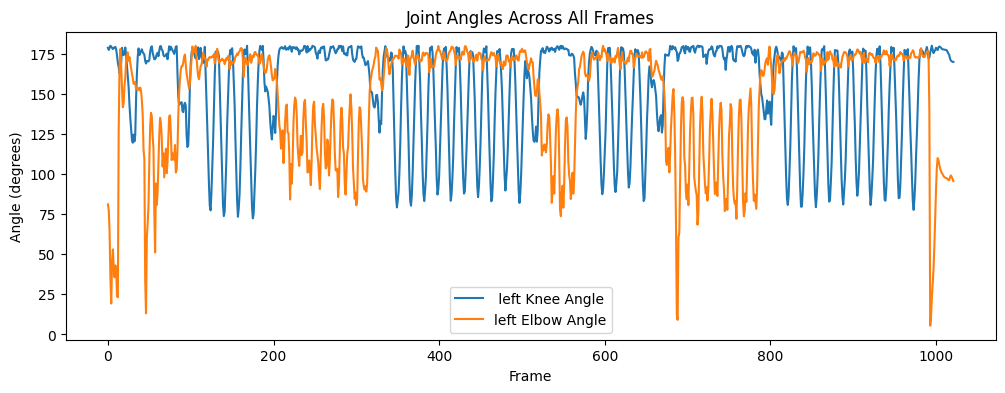

In [ ]:
# Plot both
plt.figure(figsize=(12, 4))
plt.plot(left_knee_angles,  label=" left Knee Angle")
plt.plot(left_elbow_angles, label="left Elbow Angle")
plt.title("Joint Angles Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

The elbow angle (orange) drops extremely low, sometimes near 0°–25° which is physically impossible for a real elbow. This confirms the left side joints are hidden from the camera and YOLO is just guessing, so its unreliable to use the left side angles.


In [ ]:
#right side will be used for counting , its more reliable since its showing in camera

#right elbow
RIGHT_SHOULDER = 6
RIGHT_ELBOW    = 8
RIGHT_WRIST    = 10

right_elbow_angles = []

for kps in smoothed_keypoints:
    if kps is None:
        right_elbow_angles.append(np.nan)
        continue
    right_elbow_angles.append(calculate_angle(kps[RIGHT_SHOULDER], kps[RIGHT_ELBOW], kps[RIGHT_WRIST]))


#right knee
RIGHT_HIP   = 12
RIGHT_KNEE  = 14
RIGHT_ANKLE = 16

right_knee_angles = []
for kps in smoothed_keypoints:
    if kps is None:
        right_knee_angles.append(np.nan)
        continue
    right_knee_angles.append(calculate_angle(kps[RIGHT_HIP], kps[RIGHT_KNEE], kps[RIGHT_ANKLE]))


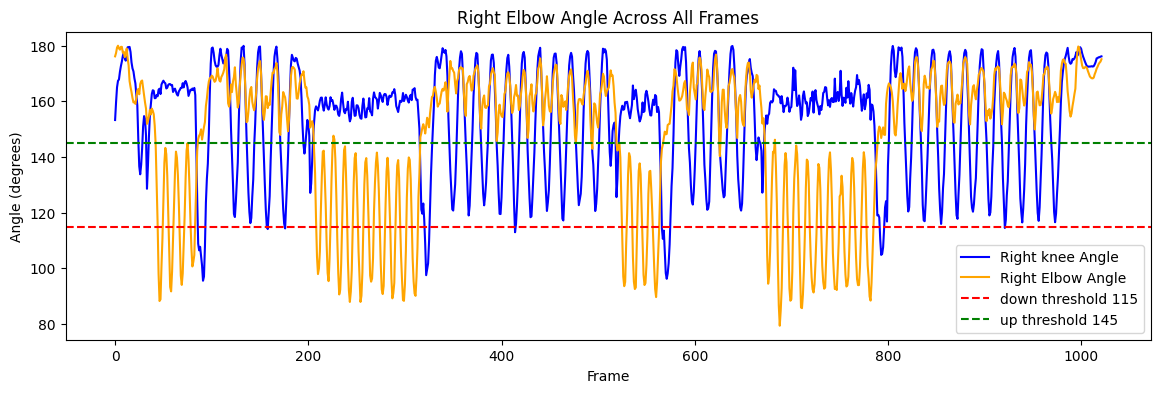

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(right_knee_angles, label="Right knee Angle", color="blue")
plt.plot(right_elbow_angles, label="Right Elbow Angle", color="orange")
plt.axhline(y=115, color="red",   linestyle="--", label="down threshold 115")
plt.axhline(y=145, color="green", linestyle="--", label="up threshold 145")
plt.title("Right Elbow Angle Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

observation on pushup: The elbow angle stays in a realistic range of 80°–180°, with clean consistent dips representing actual push-up reps. The thresholds (115° down, 145° up) make sense and align with the dips.

 observation on squat: Dips are shallower, only reaching 100°–115°+ more noisy and irregular
Barely crosses the down threshold

Reliability observation:

For the squat , well use left knee as opposed to right as the dips are more reliable/less noisy and less spikes and more consistent

for pushup , well use right elbow , more consistent and less spikes as well as opposed to left.

# Repetition Counting
Tracks a key joint angle over time and counts how many times it crosses a threshold (down → up = 1 rep).

In [ ]:
def count_reps_stable(angles, down_threshold, up_threshold, min_frames_down=3):
    reps = 0
    state = "up"
    frames_down = 0

    for angle in angles:
        if np.isnan(angle):
            continue

        if state == "up" and angle < down_threshold:
            frames_down += 1
            if frames_down >= min_frames_down:
                state = "down"
        elif state == "up":
            frames_down = 0

        elif state == "down" and angle > up_threshold:
            state = "up"
            frames_down = 0
            reps += 1

    return reps

# knee must go below 120° to count as squatting down, using left knee for squat since its more clear in angle in video
squat_reps  = count_reps_stable(left_knee_angles,  down_threshold=120, up_threshold=150, min_frames_down=3)
# knee must come back above 150° to count as standing up, using right elbow in pushup since its more clear in angle in video
pushup_reps = count_reps_stable(right_elbow_angles, down_threshold=115, up_threshold=130, min_frames_down=2)

print(f"Squat reps  : {squat_reps}")
print(f"Push-up reps: {pushup_reps}")

Squat reps  : 28
Push-up reps: 28


# Form Assessment

In [ ]:
def assess_form(angles, down_threshold, good_form_threshold, up_threshold, min_frames_down=3):
    """
    Counts total reps and good form reps.
    good_form_threshold : the angle must go BELOW this to count as good form
    """
    reps = 0
    good_reps = 0
    state = "up"
    frames_down = 0
    min_angle_in_rep = 180  # track deepest point of each rep

    for angle in angles:
        if np.isnan(angle):
            continue

        if state == "up" and angle < down_threshold:
            frames_down += 1
            if frames_down >= min_frames_down:
                state = "down"
                min_angle_in_rep = angle
        elif state == "up":
            frames_down = 0

        elif state == "down":
            min_angle_in_rep = min(min_angle_in_rep, angle)
            if angle > up_threshold:
                state = "up"
                frames_down = 0
                reps += 1
                if min_angle_in_rep < good_form_threshold:
                    good_reps += 1
                min_angle_in_rep = 180

    return reps, good_reps


# Run form assessment
squat_total,  squat_good  = assess_form(left_knee_angles,        down_threshold=120, good_form_threshold=86, up_threshold=150, min_frames_down=3)
pushup_total, pushup_good = assess_form(right_elbow_angles, down_threshold=115, good_form_threshold=94, up_threshold=130, min_frames_down=2)

print(f"Squats   — Total: {squat_total}  | Good form: {squat_good}  | Bad form: {squat_total  - squat_good}")
print(f"Push-ups — Total: {pushup_total} | Good form: {pushup_good} | Bad form: {pushup_total - pushup_good}")

Squats   — Total: 28  | Good form: 21  | Bad form: 7
Push-ups — Total: 28 | Good form: 22 | Bad form: 6


# JSON Output

In [ ]:
# Calculate final counts based on the 'harder' evaluation standards
output = {
    "video_id": str(uuid.uuid4()),
    "summary": {
        "squats": {
            "total_reps": squat_total,
            "good_form_reps": squat_good,
            "bad_form_reps": squat_total - squat_good
        },
        "pushups": {
            "total_reps": pushup_total,
            "good_form_reps": pushup_good,
            "bad_form_reps": pushup_total - pushup_good
        }
    }
}

# Print formatted JSON to the console
print("Exercise Summary Report:")
print(json.dumps(output, indent=4))

# Save to the physical file
with open("exercise_output_both_exercises_perfect_form.json", "w") as f:
    json.dump(output, f, indent=4)

print("\nexercise_output.json has been generated successfully!")

Exercise Summary Report:
{
    "video_id": "540130d5-0ffc-4596-b3ae-f1610fa088c3",
    "summary": {
        "squats": {
            "total_reps": 28,
            "good_form_reps": 21,
            "bad_form_reps": 7
        },
        "pushups": {
            "total_reps": 28,
            "good_form_reps": 22,
            "bad_form_reps": 6
        }
    }
}

exercise_output.json has been generated successfully!


# Annotated Output Video

In [ ]:
# Reset all counters and states
squat_state = "up"
pushup_state = "up"
squat_count = 0
pushup_count = 0
squat_frames_down = 0
pushup_frames_down = 0
squat_good_count = 0
squat_bad_count = 0
pushup_good_count = 0
pushup_bad_count = 0
squat_min_angle = 180
pushup_min_angle = 180

display_squat_form = "---"
display_pushup_form = "---"
display_squat_phase = "Standing"
display_pushup_phase = "Resting"
squat_form_color = (255, 255, 255)
pushup_form_color = (255, 255, 255)
squat_phase_color = (255, 255, 255)
pushup_phase_color = (255, 255, 255)

frame_idx = 0
kps_idx = 0

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter("annotated_output.mp4",
                      cv2.VideoWriter_fourcc(*"mp4v"),
                      fps, (width, height))

SKELETON = [
    (5, 7), (7, 9),
    (6, 8), (8, 10),
    (5, 6),
    (5, 11), (6, 12),
    (11, 12),
    (11, 13), (13, 15),
    (12, 14), (14, 16)
]

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_idx % 2 == 0 and kps_idx < len(smoothed_keypoints):
        kps = smoothed_keypoints[kps_idx]
        kps_idx += 1

        if kps is not None:
            # Draw skeleton
            for (i, j) in SKELETON:
                x1, y1 = int(kps[i][0]), int(kps[i][1])
                x2, y2 = int(kps[j][0]), int(kps[j][1])
                if x1 > 0 and y1 > 0 and x2 > 0 and y2 > 0:
                    cv2.line(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

            # Draw keypoints
            for k in range(len(kps)):
                x, y = int(kps[k][0]), int(kps[k][1])
                if x > 0 and y > 0:
                    cv2.circle(frame, (x, y), 4, (0, 0, 255), -1)

            # Calculate angles
            knee_angle = calculate_angle(kps[11], kps[13], kps[15])
            elbow_angle = calculate_angle(kps[6], kps[8], kps[10])

            # Squat state machine
            if squat_state == "up" and knee_angle < 120:
                squat_frames_down += 1
                display_squat_phase = "Going Down"
                squat_phase_color = (0, 165, 255)
                if squat_frames_down >= 3:
                    squat_state = "down"
                    squat_min_angle = knee_angle
            elif squat_state == "up":
                squat_frames_down = 0
                display_squat_phase = "Standing"
                squat_phase_color = (255, 255, 255)
            elif squat_state == "down":
                squat_min_angle = min(squat_min_angle, knee_angle)
                if knee_angle > 150:
                    squat_state = "up"
                    squat_frames_down = 0
                    squat_count += 1
                    display_squat_phase = "Going Up"
                    squat_phase_color = (0, 255, 0)
                    display_squat_form = "Good" if squat_min_angle < 86 else "Bad"
                    squat_form_color   = (0, 255, 0) if display_squat_form == "Good" else (0, 0, 255)
                    if display_squat_form == "Good":
                        squat_good_count += 1
                    else:
                        squat_bad_count  += 1
                    squat_min_angle = 180
                else:
                    display_squat_phase = "Going Down"
                    squat_phase_color = (0, 165, 255)

            # Push-up state machine
            if pushup_state == "up" and elbow_angle < 115:
                pushup_frames_down += 1
                display_pushup_phase = "Going Down"
                pushup_phase_color = (0, 165, 255)
                if pushup_frames_down >= 2:
                    pushup_state = "down"
                    pushup_min_angle = elbow_angle
            elif pushup_state == "up":
                pushup_frames_down = 0
                display_pushup_phase = "Resting"
                pushup_phase_color = (255, 255, 255)
            elif pushup_state == "down":
                pushup_min_angle = min(pushup_min_angle, elbow_angle)
                if elbow_angle > 130:
                    pushup_state = "up"
                    pushup_frames_down = 0
                    pushup_count += 1
                    display_pushup_phase = "Going Up"
                    pushup_phase_color = (0, 255, 0)
                    display_pushup_form = "Good" if pushup_min_angle < 94 else "Bad"
                    pushup_form_color   = (0, 255, 0) if display_pushup_form == "Good" else (0, 0, 255)
                    if display_pushup_form == "Good":
                        pushup_good_count += 1
                    else:
                        pushup_bad_count  += 1
                    pushup_min_angle = 180
                else:
                    display_pushup_phase = "Going Down"
                    pushup_phase_color = (0, 165, 255)

    # Draw overlay
    cv2.rectangle(frame, (0, 0), (420, 230), (0, 0, 0), -1)
    cv2.putText(frame, f"Squats   : {squat_count}  G:{squat_good_count} B:{squat_bad_count}", (10, 30),  cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0),      2)
    cv2.putText(frame, f"Form     : {display_squat_form}", (10, 60),  cv2.FONT_HERSHEY_SIMPLEX, 0.8, squat_form_color,  2)
    cv2.putText(frame, f"Phase    : {display_squat_phase}", (10, 90),  cv2.FONT_HERSHEY_SIMPLEX, 0.8, squat_phase_color, 2)
    cv2.putText(frame, f"Push-ups : {pushup_count}  G:{pushup_good_count} B:{pushup_bad_count}", (10, 140), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255),    2)
    cv2.putText(frame, f"Form     : {display_pushup_form}", (10, 170), cv2.FONT_HERSHEY_SIMPLEX, 0.8, pushup_form_color, 2)
    cv2.putText(frame, f"Phase    : {display_pushup_phase}",(10, 200), cv2.FONT_HERSHEY_SIMPLEX, 0.8, pushup_phase_color,2)

    out.write(frame)
    frame_idx += 1

cap.release()
out.release()
print(f"annotated_output.mp4 saved \u2705")
print(f"Final \u2014 Squats: {squat_count} | Push-ups: {pushup_count}")

annotated_output.mp4 saved ✅
Final — Squats: 28 | Push-ups: 28


# Now well observe a bad form pushup and squat video

In [ ]:
video_path = "/content/bad_pushup_video.mp4"
fps, width, height, total = upload_video(video_path)


FPS     : 30.00098687456824
Size    : 2046 x 1456
Frames  : 304


In [ ]:
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

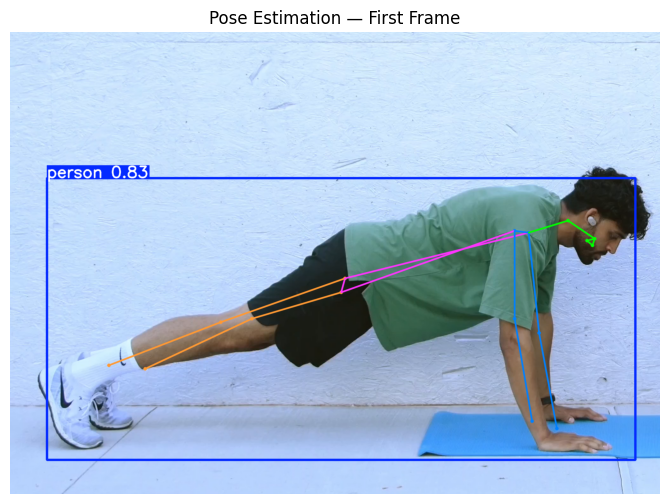

In [ ]:
results = model(frame, verbose=False)

# Plot keypoints on the frame
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Pose Estimation — First Frame")
plt.show()

In [ ]:
all_keypoints = [] #will store keypoint for all our frames
current_frame = 0

cap = cv2.VideoCapture(video_path)

while True:
    ret, frame = cap.read() # ret short for return ,boolean returned by cap.read,
    # ret= true means frame was read successfully
    if not ret:
        break

    if current_frame % 2 == 0: # only process even frames
        results = model(frame, verbose=False)  # runs YOLOv8 pose
        if results[0].keypoints is not None and len(results[0].keypoints.xy) > 0:
            kps = results[0].keypoints.xy[0].cpu().numpy() # extracts (x,y) of 17 keypoints
        else:
            kps = None # if no person detected, store None
        all_keypoints.append(kps)

    current_frame+= 1

cap.release()
print(f"Processed frames: {len(all_keypoints)}")

Processed frames: 152


In [ ]:
smoothed_keypoints = smooth_keypoints(all_keypoints, alpha=0.5)

print(f"Total smoothed frames : {len(smoothed_keypoints)}")

Total smoothed frames : 152


In [ ]:
LEFT_SHOULDER = 5
LEFT_ELBOW    = 7
LEFT_WRIST    = 9

kps = smoothed_keypoints[100]  # pick any frame

left_elbow_angle  = calculate_angle(kps[LEFT_SHOULDER], kps[LEFT_ELBOW], kps[LEFT_WRIST])

print(f"Elbow angle : {left_elbow_angle:.1f}°")

Elbow angle : 139.4°


In [ ]:
#left side

left_elbow_angles_pushup = []

#calculate_angle on every frame of the video
for kps in smoothed_keypoints:
    if kps is None:  # no person detected this frame
        left_elbow_angles.append(np.nan)
        continue

    left_elbow_angles_pushup.append(calculate_angle(kps[LEFT_SHOULDER], kps[LEFT_ELBOW], kps[LEFT_WRIST]))

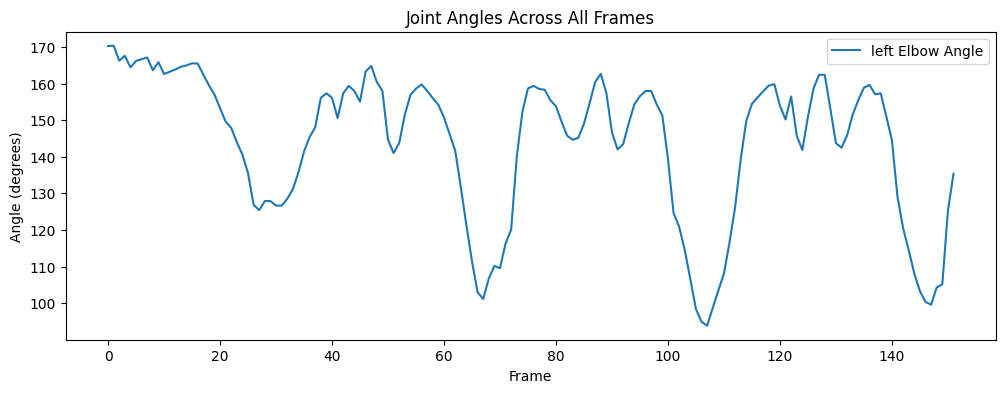

In [ ]:
# Plot both
plt.figure(figsize=(12, 4))
plt.plot(left_elbow_angles_pushup, label="left Elbow Angle")
plt.title("Joint Angles Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

In [ ]:
#right side will be used for counting , its more reliable since its showing in camera

#right elbow
RIGHT_SHOULDER = 6
RIGHT_ELBOW    = 8
RIGHT_WRIST    = 10

right_elbow_angles_pushup = []

for kps in smoothed_keypoints:
    if kps is None:
        right_elbow_angles_pushup.append(np.nan)
        continue
    right_elbow_angles_pushup.append(calculate_angle(kps[RIGHT_SHOULDER], kps[RIGHT_ELBOW], kps[RIGHT_WRIST]))


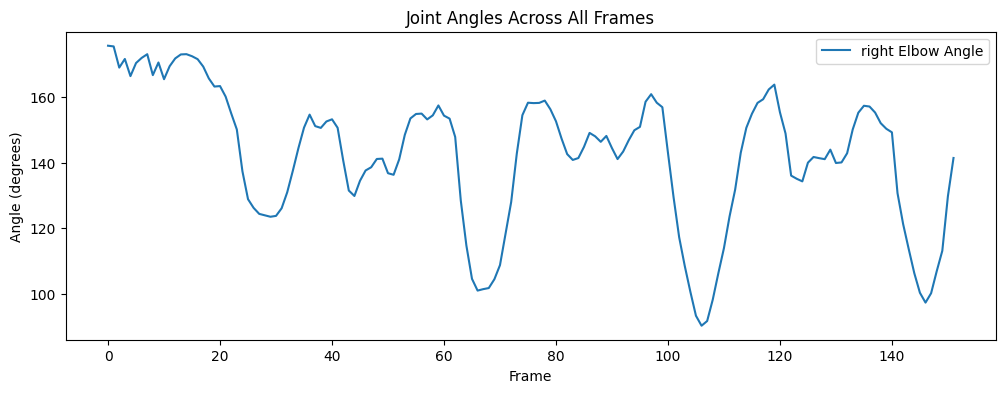

In [ ]:
# Plot both
plt.figure(figsize=(12, 4))
plt.plot(right_elbow_angles_pushup, label="right Elbow Angle")
plt.title("Joint Angles Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

right side is smoother and less spikes , Drops to 0°–25° which is physically impossible, so use right elbow

In [ ]:
# knee must come back above 150° to count as standing up, using right elbow in pushup since its more clear in angle in video
pushup_reps = count_reps_stable(right_elbow_angles_pushup, down_threshold=115, up_threshold=130, min_frames_down=2)

print(f"Push-up reps: {pushup_reps}")

Push-up reps: 3


In [ ]:
pushup_total, pushup_good = assess_form(right_elbow_angles_pushup, down_threshold=115, good_form_threshold=94, up_threshold=130, min_frames_down=2)
print(f"Push-ups — Total: {pushup_total} | Good form: {pushup_good} | Bad form: {pushup_total - pushup_good}")

Push-ups — Total: 3 | Good form: 1 | Bad form: 2


In [ ]:
# Calculate final counts based on the 'harder' evaluation standards
output = {
    "video_id": str(uuid.uuid4()),
    "summary": {
        "pushups": {
            "total_reps": pushup_total,
            "good_form_reps": pushup_good,
            "bad_form_reps": pushup_total - pushup_good
        }

    }
}

# Print formatted JSON to the console
print("Exercise Summary Report:")
print(json.dumps(output, indent=4))

# Save to the physical file
with open("exercise_output_bad_pushup.json", "w") as f:
    json.dump(output, f, indent=4)

print("\nexercise_output_bad_pushup.json has been generated successfully!")

Exercise Summary Report:
{
    "video_id": "abd09caa-09ea-4db0-88b6-45492b92e49f",
    "summary": {
        "pushups": {
            "total_reps": 3,
            "good_form_reps": 1,
            "bad_form_reps": 2
        }
    }
}

exercise_output_bad_pushup.json has been generated successfully!


Now well observe bad squat form

In [ ]:
video_path = "/content/bad_squat_video_2.mp4"
fps, width, height, total = upload_video(video_path)


FPS     : 24.0
Size    : 2160 x 3840
Frames  : 304


In [ ]:
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

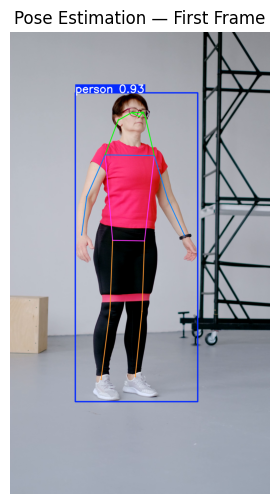

In [ ]:
results = model(frame, verbose=False)

# Plot keypoints on the frame
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Pose Estimation — First Frame")
plt.show()

In [ ]:
all_keypoints = [] #will store keypoint for all our frames
current_frame = 0

cap = cv2.VideoCapture(video_path)

while True:
    ret, frame = cap.read() # ret short for return ,boolean returned by cap.read,
    # ret= true means frame was read successfully
    if not ret:
        break

    if current_frame % 2 == 0: # only process even frames
        results = model(frame, verbose=False)  # runs YOLOv8 pose
        if results[0].keypoints is not None and len(results[0].keypoints.xy) > 0:
            kps = results[0].keypoints.xy[0].cpu().numpy() # extracts (x,y) of 17 keypoints
        else:
            kps = None # if no person detected, store None
        all_keypoints.append(kps)

    current_frame+= 1

cap.release()
print(f"Processed frames: {len(all_keypoints)}")

Processed frames: 152


In [ ]:
smoothed_keypoints = smooth_keypoints(all_keypoints, alpha=0.5)

print(f"Total smoothed frames : {len(smoothed_keypoints)}")

Total smoothed frames : 152


In [ ]:
# YOLOv8 pose keypoint indices
# 5=left shoulder, 6=right shoulder
# 7=left elbow,    8=right elbow
# 9=left wrist,    10=right wrist
# 11=left hip,     12=right hip
# 13=left knee,    14=right knee
# 15=left ankle,   16=right ankle

LEFT_HIP    = 11
LEFT_KNEE   = 13
LEFT_ANKLE  = 15


kps = smoothed_keypoints[100]  # pick any frame

left_knee_angle   = calculate_angle(kps[LEFT_HIP], kps[LEFT_KNEE], kps[LEFT_ANKLE])

print(f"Knee angle  : {knee_angle:.1f}°")

Knee angle  : 169.9°


In [ ]:
#left side

left_knee_angles_squat  = []

#calculate_angle on every frame of the video
for kps in smoothed_keypoints:
    if kps is None:  # no person detected this frame
        left_knee_angles_squat.append(np.nan)
        continue

    left_knee_angles_squat.append(calculate_angle(kps[LEFT_HIP],  kps[LEFT_KNEE],  kps[LEFT_ANKLE]))

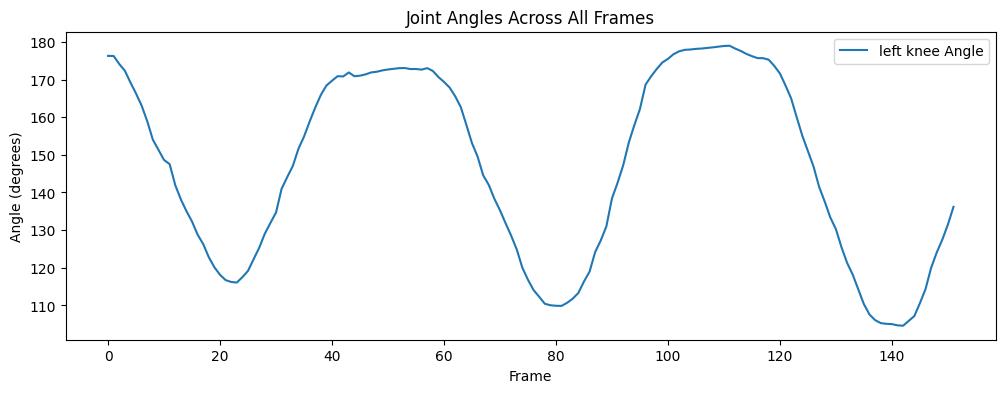

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(left_knee_angles_squat, label="left knee Angle")
plt.title("Joint Angles Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

In [ ]:
#right knee
RIGHT_HIP   = 12
RIGHT_KNEE  = 14
RIGHT_ANKLE = 16

right_knee_angles_squat = []
for kps in smoothed_keypoints:
    if kps is None:
        right_knee_angles.append(np.nan)
        continue
    right_knee_angles_squat.append(calculate_angle(kps[RIGHT_HIP], kps[RIGHT_KNEE], kps[RIGHT_ANKLE]))


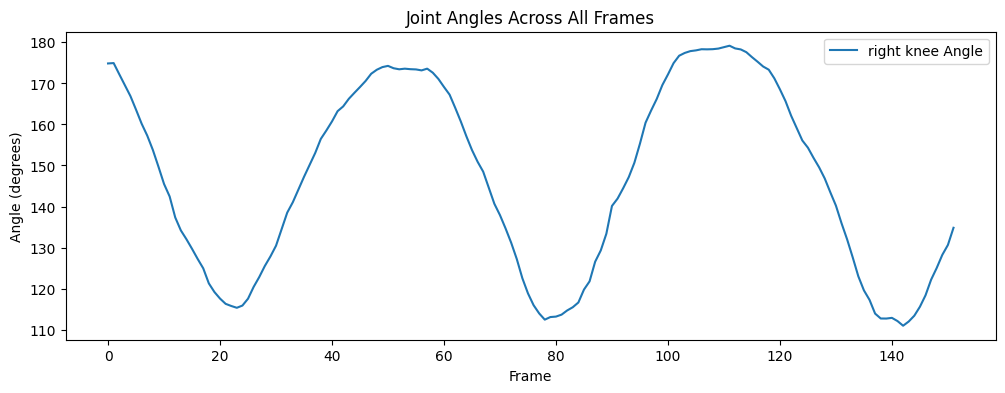

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(right_knee_angles_squat, label="right knee Angle")
plt.title("Joint Angles Across All Frames")
plt.xlabel("Frame")
plt.ylabel("Angle (degrees)")
plt.legend()
plt.show()

In [ ]:
# knee must come back above 150° to count as standing up, using right elbow in pushup since its more clear in angle in video
squat_reps  = count_reps_stable(left_knee_angles_squat,  down_threshold=120, up_threshold=150, min_frames_down=3)

print(f"squat-up reps: {squat_reps}")

squat-up reps: 2


In [ ]:
# Run form assessment
squat_total,  squat_good  = assess_form(left_knee_angles_squat,        down_threshold=120, good_form_threshold=86, up_threshold=150, min_frames_down=3)
print(f"Squats   — Total: {squat_total}  | Good form: {squat_good}  | Bad form: {squat_total  - squat_good}")


Squats   — Total: 2  | Good form: 0  | Bad form: 2


In [ ]:
# Calculate final counts based on the 'harder' evaluation standards
output = {
    "video_id": str(uuid.uuid4()),
    "summary": {
        "squats": {
            "total_reps": squat_total,
            "good_form_reps": squat_good,
            "bad_form_reps": squat_total - squat_good
        },

    }
}

# Print formatted JSON to the console
print("Exercise Summary Report:")
print(json.dumps(output, indent=4))

# Save to the physical file
with open("exercise_output_bad_squat.json", "w") as f:
    json.dump(output, f, indent=4)

print("\nexercise_output_bad_squat.json has been generated successfully!")

Exercise Summary Report:
{
    "video_id": "a6781492-9914-4300-9b78-2f67d4254947",
    "summary": {
        "squats": {
            "total_reps": 2,
            "good_form_reps": 0,
            "bad_form_reps": 2
        }
    }
}

exercise_output_bad_squat.json has been generated successfully!
